# Ejemplo R - Análisis de Correspondencia

* El objetivo de este estudio es analizar la asociación entre el nivel cultural, representado en columnas, y el trastorno de la atención en los niños, representado en filas
* Para ello, se observaron 1600 niños pacientes de un centro asistencial focalizando en su nivel cultural y
en su respuesta a un test de trastornos de la atención. ención en los niños

In [3]:
library(readxl)
library(ca)            # Paquete para análisis de correspondencias
library(FactoMineR)    # Paquete con métodos de análisis exploratorio de datos
library(factoextra)    # Paquete para análisis multivariado de datos
library(ggplot2)       # Paquete para confeccionar dibujos

In [4]:
# Armamos la base de datos
atento <-   c(64,57,57,72,36,21)
leve <-     c(94,84,105,141,97,51)
moderado <- c(58,54,85,107,67,34)
disperso <- c(46,40,60,94,78,51)

base <- rbind(atento, leve, moderado, disperso)
colnames(base) <- c("A", "B", "C", "D", "E", "F")
rownames(base) <- c("Atento", "Sint._leves", "Sint._moderados", "Disperso")

In [5]:
base

,A,B,C,D,E,F
Atento,64,57,57,72,36,21
Sint._leves,94,84,105,141,97,51
Sint._moderados,58,54,85,107,67,34
Disperso,46,40,60,94,78,51


In [14]:
# Realiza el análisis de correspondencias
atencion.ac <- CA(base, graph = FALSE)
summary(atencion.ac)


Call:
CA(X = base, graph = FALSE) 

The chi square of independence between the two variables is equal to 37.72536 (p-value =  0.0009905278 ).

Eigenvalues
                       Dim.1   Dim.2   Dim.3
Variance               0.020   0.003   0.000
% of var.             87.654  11.515   0.831
Cumulative % of var.  87.654  99.169 100.000

Rows
                  Iner*1000    Dim.1    ctr   cos2    Dim.2    ctr   cos2  
Atento          |     9.830 | -0.224 46.791  0.952 |  0.048 16.564  0.044 |
Sint._leves     |     0.285 | -0.021  0.758  0.531 |  0.006  0.457  0.042 |
Sint._moderados |     1.775 |  0.002  0.006  0.001 | -0.085 66.874  0.990 |
Disperso        |    10.932 |  0.217 52.446  0.960 |  0.044 16.105  0.039 |
                 Dim.3    ctr   cos2  
Atento           0.014 18.073  0.003 |
Sint._leves     -0.019 64.181  0.427 |
Sint._moderados  0.008  8.619  0.009 |
Disperso         0.009  9.126  0.002 |

Columns
                  Iner*1000    Dim.1    ctr   cos2    Dim.2    ctr   cos2 

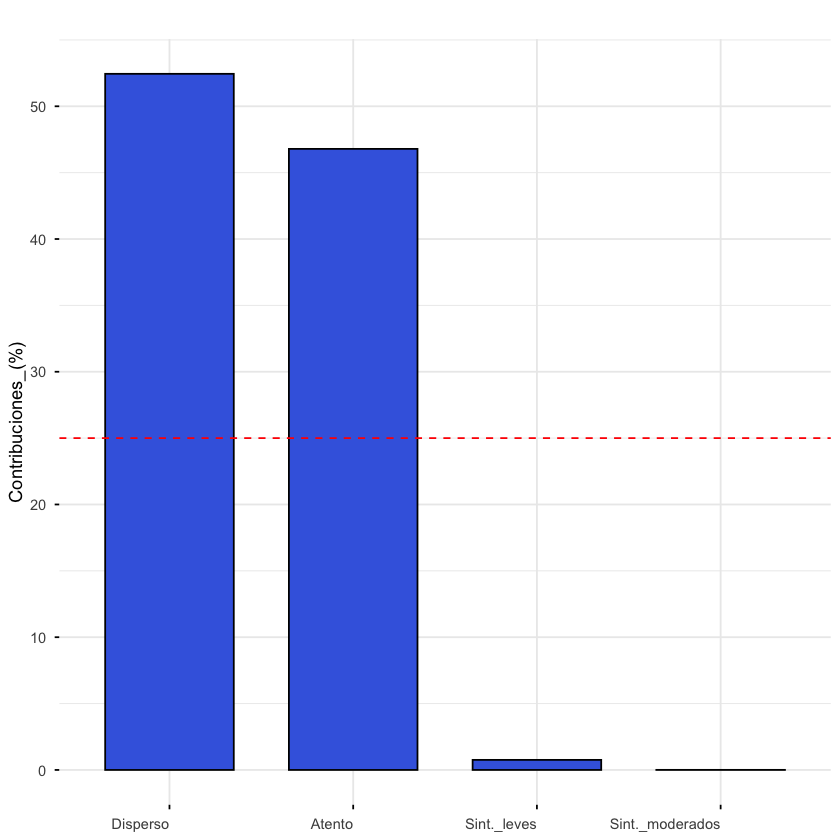

In [15]:
fviz_contrib(atencion.ac, choice = "row", axes = 1, fill = "royalblue", color = "black") +
  theme(axis.text.x = element_text(angle = 0)) +
  xlab("Nivel_de_atención") +
  ylab("Contribuciones_(%)") +
  ggtitle("")

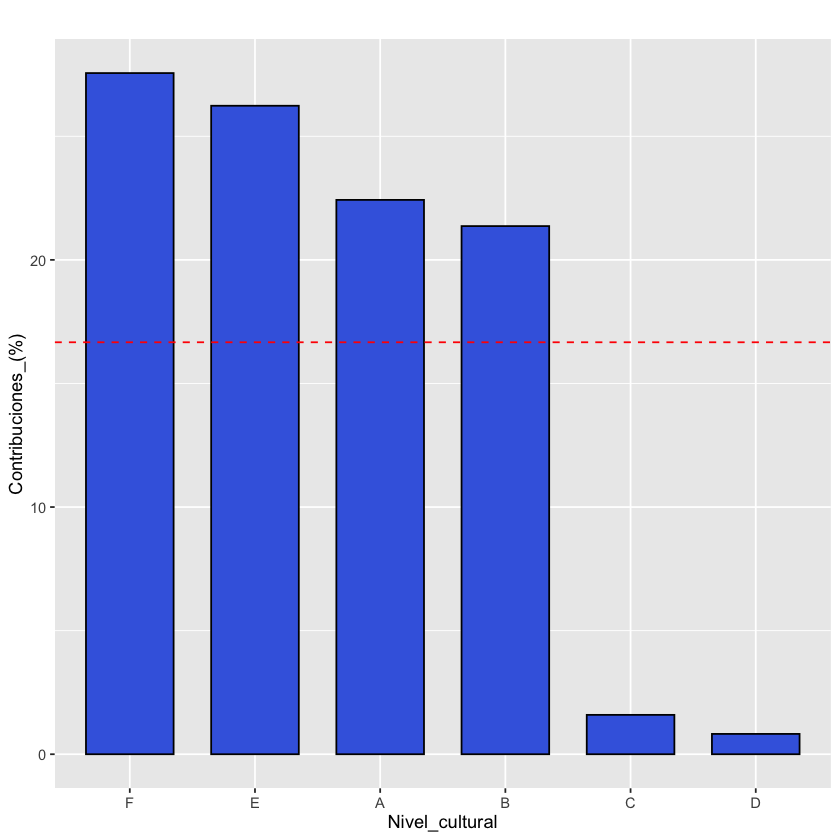

In [16]:
# Grafica las categorías de las filas
fviz_contrib(atencion.ac, choice = "col", axes = 1, fill = "royalblue", color = "black") +
  theme_gray() +
  theme_gray() +
  theme(axis.text.x = element_text(angle = 0)) +
  xlab("Nivel_cultural") +
  ylab("Contribuciones_(%)") +
  ggtitle("")

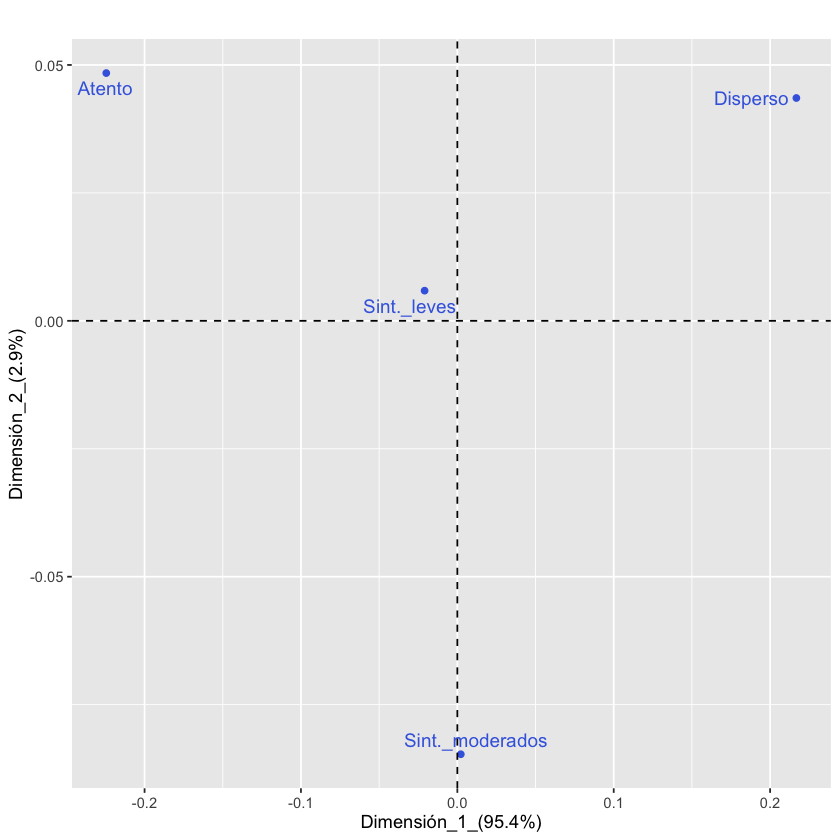

In [17]:
# Grafica las categorías de las columnas
fviz_ca_row(atencion.ac, repel = TRUE, col.row = "royalblue") +
  theme_gray() +
  xlab("Dimensión_1_(95.4%)") +
  ylab("Dimensión_2_(2.9%)") +
  ggtitle("")

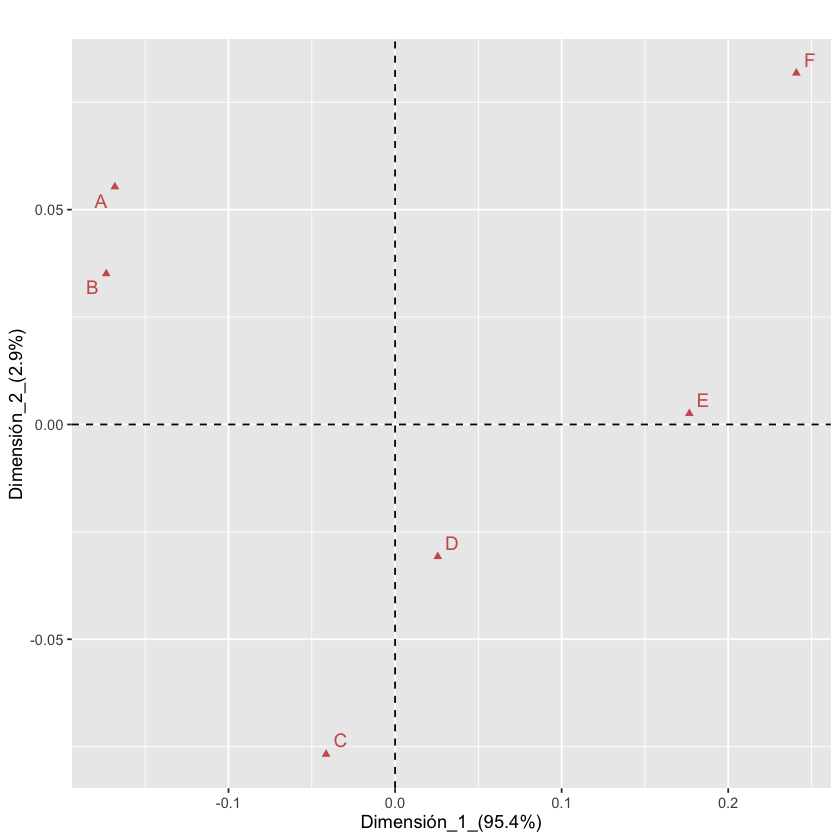

In [18]:
# Grafica los puntos fila
fviz_ca_col(atencion.ac, repel = TRUE, col.col = "indianred") +
  theme_gray() +
  xlab("Dimensión_1_(95.4%)") +
  ylab("Dimensión_2_(2.9%)") +
  ggtitle("")

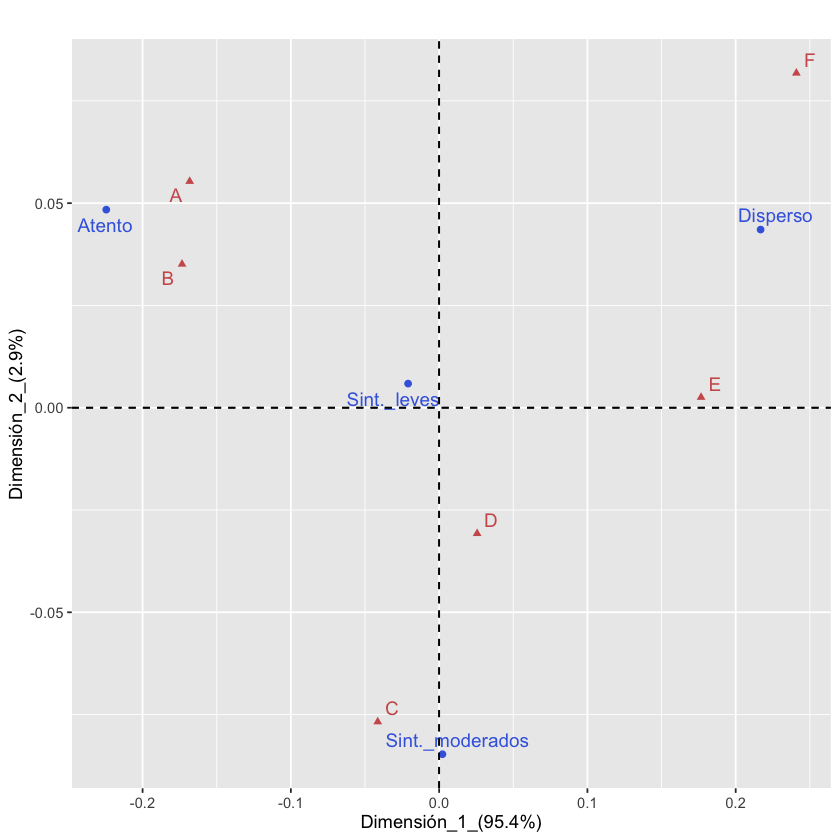

In [19]:
# Grafica los puntos columna
fviz_ca_biplot(atencion.ac, repel = TRUE, col.row = "royalblue", col.col = "indianred") +
  theme_gray() +
  xlab("Dimensión_1_(95.4%)") +
  ylab("Dimensión_2_(2.9%)") +
  ggtitle("")

* Cada eje está representando un porcentaje de inercia
    * Eje horizontal tiene una inercia del 95.4%
    * Eje vertical tiene una inercia del 2.9%
* **Atento** está mas cerca de A y B que de C, D y E

* Con el AC se construye una gráfica, llamada **mapa perceptual**, que señala la interacción de dos variables
categóricas a través de la relación entre las filas y las columnas
* Se cuantifica además el grado de asociación presente en un conjunto de variables
* Por ejemplo, consideremos la variable cualitativa fila que representa el grado de atención
* Mientras que la variable columna el nivel cultural
* El análisis de correspondencias estudia las frecuencias de la distribución conjunta de ambas variables y produce un gráfico con dos ejes en los cuales cada categoría de la variable ubicada en las filas y cada categoría de la variable ubicada en las columnas está representada por un punto

## Guía para la interpretación gráfica del biplot simétrico

1. Las columnas (respectivamente, filas) cercanas al origen reflejan categorías similares a la columna (respectivamente, fila)
promedio. El (0,0) representa una categoria promedio. Es el centro de la inercia
2. Las columnas (respectivamente, filas) cercanas entre sí reflejan categorías de similar perfil en términos de columnas
(respectivamente, filas)
3. Las columnas (respectivamente, filas) cercanas y lejanas al origen reflejan alta asociación positiva entre las categorías representadas
4. Los ejes representan "factores ocultos" o "variables latentes"
5. En cada eje se indica el porcentaje de la inercia que logra representar el mismo
6. DISTANCIAS RELATIVAS NO ABSOLUTAS
7. Se observa un punto fila en el conjunto del espacio de las columnas
8. Se observa un punto columna en el conjunto del espacio de las filas

Teniendo en cuenta lo anterior, realizamos las siguientes observaciones para el biplot simétrico:
* El nivel de atención más usual presentan síntomas leves y el nivel de cultural D (cerca de (0,0) (perfil medio)
* El nivel cultural A es el más próximo a la categoría de "atento"
* El nivel de cultura D es el más usual mas cercano al valor medio de los niveles de cultura
* Los síntomas "leves" en grado de atención se asocian con la categoría de cultura D
* Los síntomas "moderados" en grado de atención se asocian con la categoría de cultura C